In [8]:
# Basic Libraries
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt # we only need pyplot
sb.set() # set the default Seaborn style for graphics

In [9]:
dataset = pd.read_csv('chatgpt_detection_results.csv')
dataset.head()

,submission_id,tool,actual_type,detected_as_ai,confidence_score,text_length,subject,grade_level,writing_style_score,perplexity_score,detection_probability
0,SUB0000,Copyleaks,ai_generated,False,0.230527,4354,HIST,Graduate,0.371146,0.381355,0.653511
1,SUB0001,Copyleaks,human_written,False,0.643546,1056,PSYCH,Graduate,0.528367,0.248499,0.010329
2,SUB0002,Originality.ai,human_written,False,0.619367,2145,PSYCH,Freshman,0.254359,0.311960,0.009575
3,SUB0003,Copyleaks,human_written,False,0.570965,1579,MATH,Freshman,0.575367,0.263869,0.018074
4,SUB0004,GPTZero,human_written,False,0.335957,3153,BIO,Graduate,0.310787,0.350734,0.121960


#Data Cleaning and Quality Check

In [20]:
# Dataset Info
print('Dataset info:', dataset.info)

# Dataset size
print("Dataset shape:", dataset.shape)

# Missing values
print(dataset.isnull().sum())

# Duplicate records
print("Duplicate rows:", dataset.duplicated().sum())

# Data types
print(dataset.dtypes)


Dataset info: <bound method DataFrame.info of      submission_id            tool    actual_type  detected_as_ai  \
0          SUB0000       Copyleaks   ai_generated           False   
1          SUB0001       Copyleaks  human_written           False   
2          SUB0002  Originality.ai  human_written           False   
3          SUB0003       Copyleaks  human_written           False   
4          SUB0004         GPTZero  human_written           False   
...            ...             ...            ...             ...   
4995       SUB4995       Copyleaks  human_written           False   
4996       SUB4996  Originality.ai  human_written           False   
4997       SUB4997         GPTZero   ai_generated            True   
4998       SUB4998       Copyleaks  human_written           False   
4999       SUB4999       Copyleaks   ai_generated            True   

      confidence_score  text_length subject grade_level  writing_style_score  \
0             0.230527         4354    HIST  

Exploratory Data Analysis

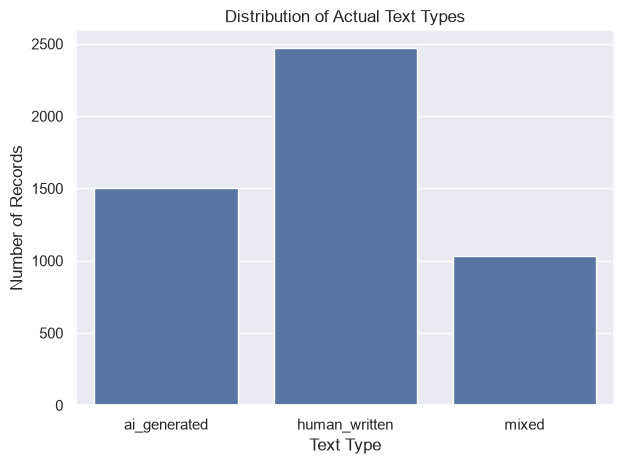

In [93]:
sb.countplot(data = dataset, x = "actual_type")
plt.title("Distribution of Actual Text Types")
plt.xlabel("Text Type")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [94]:
# Flagging rate by actual type and by tool
flag_rates = (
    dataset.groupby("actual_type", observed=False)["detected_as_ai"]
    .agg(submissions="size", flagged_rate="mean")
    .reset_index()
)
flag_rates["flagged_rate_pct"] = 100 * flag_rates["flagged_rate"]
display(flag_rates[["actual_type", "submissions", "flagged_rate_pct"]].round(1))


,actual_type,submissions,flagged_rate_pct
0,ai_generated,1500,85.4
1,human_written,2469,6.8
2,mixed,1031,43.5


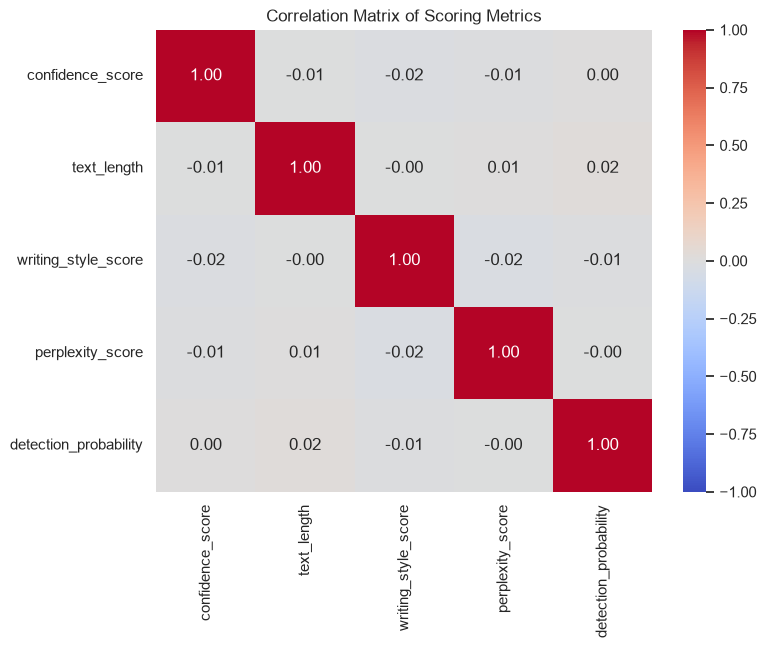

In [95]:
plt.figure(figsize=(8, 6))
cols = ['confidence_score', 'text_length', 'writing_style_score', 'perplexity_score', 'detection_probability']

sns.heatmap(
    df[cols].corr(), 
    annot=True, 
    cmap='coolwarm', 
    fmt=".2f", 
    vmin=-1, 
    vmax=1
)
plt.title("Correlation Matrix of Scoring Metrics")
plt.show()

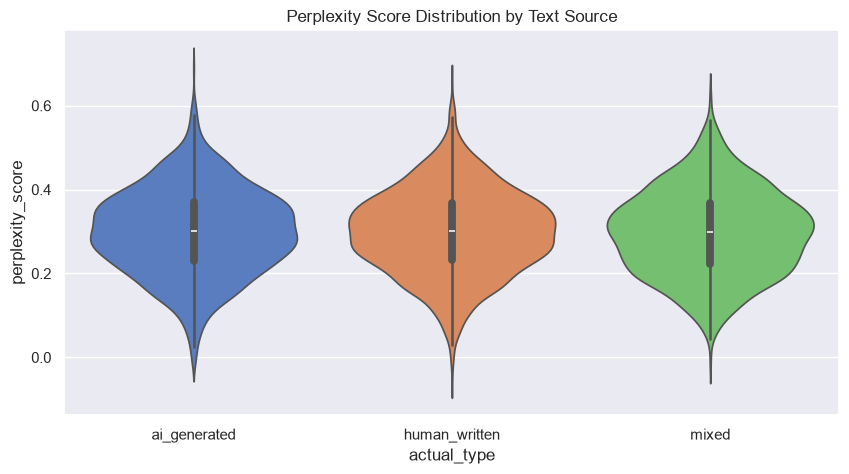

In [96]:
plt.figure(figsize=(10, 5))
sb.violinplot(
    data=dataset, 
    x='actual_type', 
    y='perplexity_score',
    palette='muted',
    hue='actual_type',
    legend=False
)
plt.title("Perplexity Score Distribution by Text Source")
plt.show()

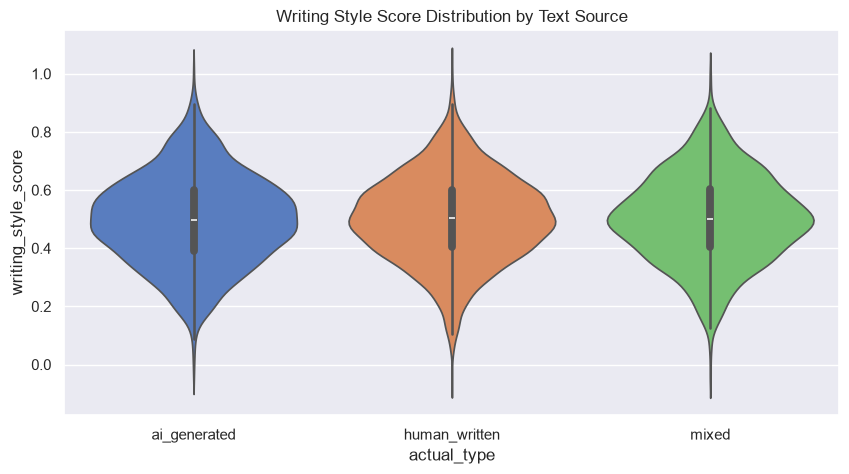

In [97]:
plt.figure(figsize=(10, 5))
sb.violinplot(
    data=dataset, 
    x='actual_type', 
    y='writing_style_score',
    palette='muted',
    hue='actual_type',
    legend=False
)
plt.title("Writing Style Score Distribution by Text Source")
plt.show()

Model Building & Evaluation

In [12]:
#Remove mixed from actual_type, to make it easier to detect AI or human
dataset_binary = dataset[dataset['actual_type'].isin(['ai_generated', 'human_written'])].copy()
dataset_binary.head()
dataset_binary.info()

<class 'pandas.DataFrame'>
Index: 3969 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   submission_id          3969 non-null   str    
 1   tool                   3969 non-null   str    
 2   actual_type            3969 non-null   str    
 3   detected_as_ai         3969 non-null   bool   
 4   confidence_score       3969 non-null   float64
 5   text_length            3969 non-null   int64  
 6   subject                3969 non-null   str    
 7   grade_level            3969 non-null   str    
 8   writing_style_score    3969 non-null   float64
 9   perplexity_score       3969 non-null   float64
 10  detection_probability  3969 non-null   float64
dtypes: bool(1), float64(4), int64(1), str(5)
memory usage: 503.5 KB


1st Test: Perplexity Score, Text Length & Writing Style Score

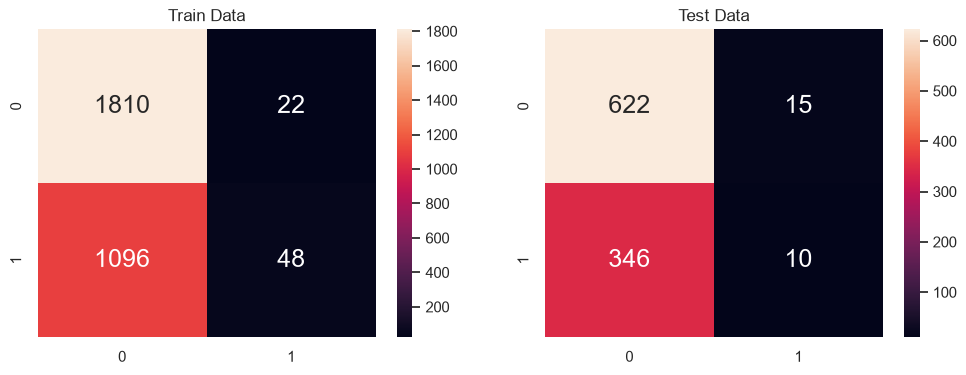

Test Data Metrics -> Precision: 0.40 | Recall: 0.03 | F1: 0.05

Goodness of Fit of Model 	Train Dataset
Classification Accuracy 	: 0.6243279569892473

Goodness of Fit of Model 	Test Dataset
Classification Accuracy 	: 0.6364551863041289


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix


X = dataset_binary[['perplexity_score', 'writing_style_score', 'text_length']]
y = dataset_binary['actual_type']

# Added random_state for reproducible splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

dectree = DecisionTreeClassifier(max_depth = 3)
dectree.fit(X_train, y_train) 

y_train_pred = dectree.predict(X_train)
y_test_pred = dectree.predict(X_test)

f, axes = plt.subplots(1, 2, figsize=(12, 4))
sb.heatmap(confusion_matrix(y_train, y_train_pred, labels=['human_written', 'ai_generated']),
           annot = True, fmt=".0f", annot_kws={"size": 18}, ax = axes[0])
axes[0].set_title('Train Data')

sb.heatmap(confusion_matrix(y_test, y_test_pred, labels=['human_written', 'ai_generated']), 
           annot = True, fmt=".0f", annot_kws={"size": 18}, ax = axes[1])
axes[1].set_title('Test Data')
plt.show()


cm = confusion_matrix(y_test, y_test_pred, labels=['human_written', 'ai_generated'])

# .ravel() flattens the 2x2 matrix into 4 individual variables
TN, FP, FN, TP = cm.ravel()

# Manual Formulas
precision = TP / (TP + FP) 
recall = TP / (TP + FN) 
f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

print(f"Test Data Metrics -> Precision: {precision:.2f} | Recall: {recall:.2f} | F1: {f1:.2f}\n")

print("Goodness of Fit of Model \tTrain Dataset")
print("Classification Accuracy \t:", dectree.score(X_train, y_train))
print()

print("Goodness of Fit of Model \tTest Dataset")
print("Classification Accuracy \t:", dectree.score(X_test, y_test))

2nd Test: Perplexity Score, Text Length, Writing Score, Subject and Grade Level

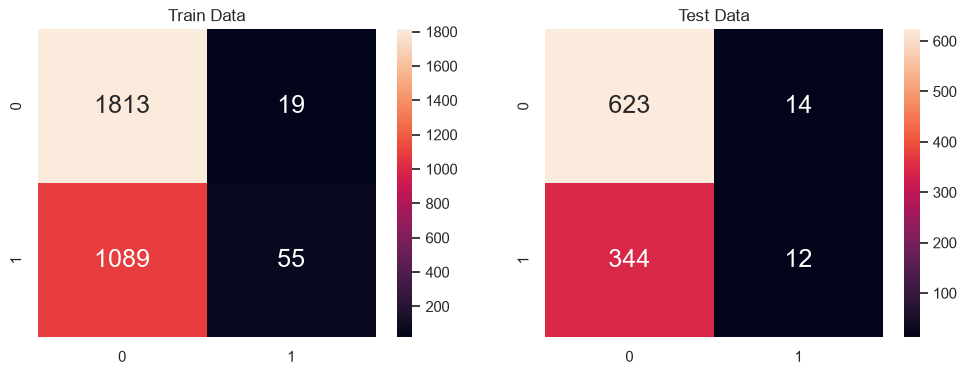

Test Data Metrics -> Precision: 0.46 | Recall: 0.03 | F1: 0.06

Goodness of Fit of Model 	Train Dataset
Classification Accuracy 	: 0.6276881720430108

Goodness of Fit of Model 	Test Dataset
Classification Accuracy 	: 0.6394763343403826


In [16]:
# Data Preprocessing 
dataset_binary = dataset[dataset['actual_type'].isin(['ai_generated', 'human_written'])].copy()

# Convert categorical text columns into 1s and 0s
dataset_binary = pd.get_dummies(dataset_binary, columns=['subject', 'grade_level'], drop_first=True)

# Now include all these new columns in X
X = dataset_binary.drop(columns=['submission_id', 'tool', 'actual_type', 'detected_as_ai', 'confidence_score', 'detection_probability'])
y = dataset_binary['actual_type']

# Added random_state for reproducible splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

dectree = DecisionTreeClassifier(max_depth = 4)
dectree.fit(X_train, y_train) 

y_train_pred = dectree.predict(X_train)
y_test_pred = dectree.predict(X_test)

f, axes = plt.subplots(1, 2, figsize=(12, 4))
sb.heatmap(confusion_matrix(y_train, y_train_pred, labels=['human_written', 'ai_generated']),
           annot = True, fmt=".0f", annot_kws={"size": 18}, ax = axes[0])
axes[0].set_title('Train Data')

sb.heatmap(confusion_matrix(y_test, y_test_pred, labels=['human_written', 'ai_generated']), 
           annot = True, fmt=".0f", annot_kws={"size": 18}, ax = axes[1])
axes[1].set_title('Test Data')
plt.show()

cm = confusion_matrix(y_test, y_test_pred, labels=['human_written', 'ai_generated'])

# .ravel() flattens the 2x2 matrix into 4 individual variables
TN, FP, FN, TP = cm.ravel()

# Manual Formulas
precision = TP / (TP + FP) 
recall = TP / (TP + FN) 
f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

print(f"Test Data Metrics -> Precision: {precision:.2f} | Recall: {recall:.2f} | F1: {f1:.2f}\n")

print("Goodness of Fit of Model \tTrain Dataset")
print("Classification Accuracy \t:", dectree.score(X_train, y_train))
print()

print("Goodness of Fit of Model \tTest Dataset")
print("Classification Accuracy \t:", dectree.score(X_test, y_test))


2nd Test (Using Random Forest Classifier)

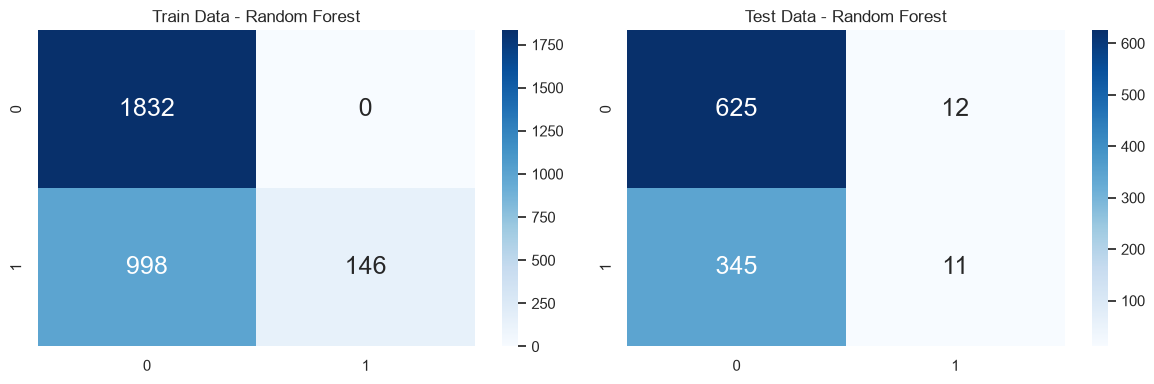

Test Data Metrics -> Precision: 0.48 | Recall: 0.03 | F1: 0.06

Goodness of Fit of Model 	Train Dataset
Classification Accuracy 	: 0.6647

Goodness of Fit of Model 	Test Dataset
Classification Accuracy 	: 0.6405


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

# 1. Data Preprocessing 
dataset_binary = dataset[dataset['actual_type'].isin(['ai_generated', 'human_written'])].copy()

# Convert categorical text columns into 1s and 0s
dataset_binary = pd.get_dummies(dataset_binary, columns=['subject', 'grade_level'], drop_first=True)

# Define X and y
X = dataset_binary.drop(columns=['submission_id', 'tool', 'actual_type', 'detected_as_ai', 'confidence_score', 'detection_probability'])
y = dataset_binary['actual_type']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# 2. Train the Random Forest Model
# n_estimators=100 means we are building a "forest" of 100 decision trees
rf_model = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)
rf_model.fit(X_train, y_train) 

# 3. Generate Predictions
y_train_pred = rf_model.predict(X_train)
y_test_pred = rf_model.predict(X_test)

# 4. Visualize with Confusion Matrices
f, axes = plt.subplots(1, 2, figsize=(12, 4))
sb.heatmap(confusion_matrix(y_train, y_train_pred, labels=['human_written', 'ai_generated']),
           annot=True, fmt=".0f", annot_kws={"size": 18}, ax=axes[0], cmap="Blues")
axes[0].set_title('Train Data - Random Forest')

sb.heatmap(confusion_matrix(y_test, y_test_pred, labels=['human_written', 'ai_generated']), 
           annot=True, fmt=".0f", annot_kws={"size": 18}, ax=axes[1], cmap="Blues")
axes[1].set_title('Test Data - Random Forest')
plt.tight_layout()
plt.show()

# 5. Model Evaluation
cm = confusion_matrix(y_test, y_test_pred, labels=['human_written', 'ai_generated'])
TN, FP, FN, TP = cm.ravel()

# Manual Formulas
precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

print(f"Test Data Metrics -> Precision: {precision:.2f} | Recall: {recall:.2f} | F1: {f1:.2f}\n")

print("Goodness of Fit of Model \tTrain Dataset")
print(f"Classification Accuracy \t: {rf_model.score(X_train, y_train):.4f}\n")

print("Goodness of Fit of Model \tTest Dataset")
print(f"Classification Accuracy \t: {rf_model.score(X_test, y_test):.4f}")

In [ ]:
2nd Study: Which AI performs best at detecting AI(ChatGPT work)

--- AI Detection Tool Performance Leaderboard ---


Rank,Tool,F1-Score,Accuracy,Precision,Recall
1,Copyleaks,0.883,91.7%,95.0%,82.6%
2,Turnitin,0.880,90.9%,90.1%,85.9%
3,GPTZero,0.863,88.1%,80.7%,92.7%
4,Winston AI,0.861,89.9%,81.8%,90.8%
5,Originality.ai,0.856,90.5%,99.1%,75.3%


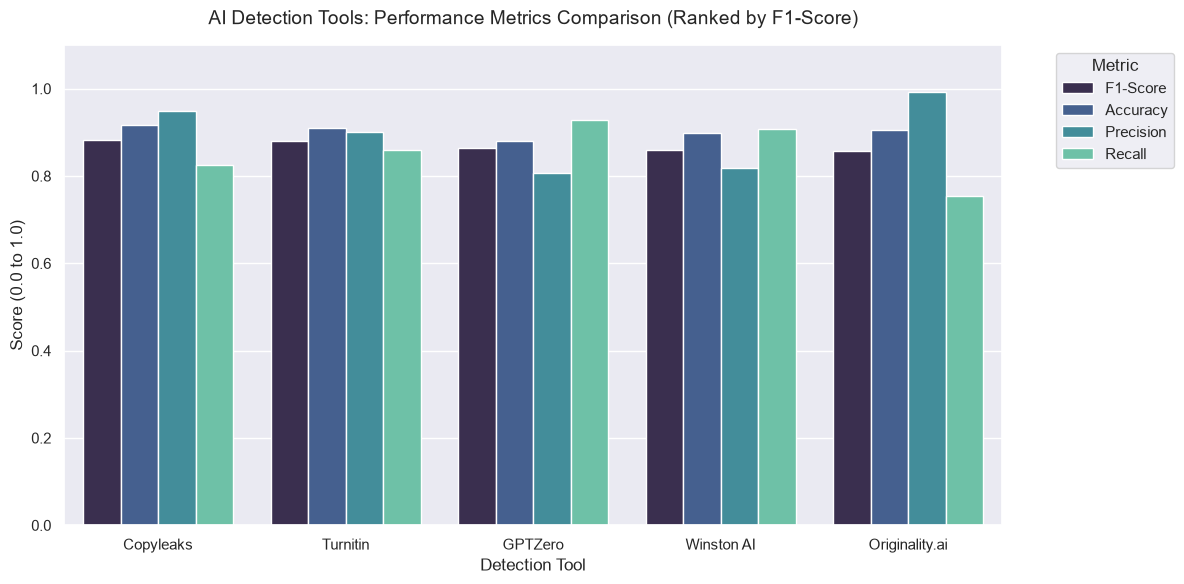

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from IPython.display import display

# 1. Load and Prepare the Dataset
dataset = pd.read_csv('chatgpt_detection_results.csv')

# Filter out 'mixed' text to create a strict Human vs. AI test
dataset = dataset[dataset['actual_type'] != 'mixed'].copy()

# Map strings to binary numbers (1 for AI, 0 for Human)
dataset['is_ai_actual'] = (dataset['actual_type'] == 'ai_generated').astype(int)
dataset['is_ai_predicted'] = dataset['detected_as_ai'].astype(int)

# 2. Calculate Metrics for Each Tool
results = []
for tool in dataset['tool'].unique():
    tool_data = dataset[dataset['tool'] == tool]
    
    y_true = tool_data['is_ai_actual']
    y_pred = tool_data['is_ai_predicted']
    
    results.append({
        'Tool': tool,
        'F1-Score': f1_score(y_true, y_pred, zero_division=0),
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0)
    })

# 3. Format and Rank the Data
results_df = pd.DataFrame(results).sort_values(by='F1-Score', ascending=False)
results_df.insert(0, 'Rank', range(1, len(results_df) + 1))

# Create a display copy to format strings as percentages for the text table
display_df = results_df.copy()
display_df['F1-Score'] = display_df['F1-Score'].apply(lambda x: f"{x:.3f}")
display_df['Accuracy'] = display_df['Accuracy'].apply(lambda x: f"{x*100:.1f}%")
display_df['Precision'] = display_df['Precision'].apply(lambda x: f"{x*100:.1f}%")
display_df['Recall'] = display_df['Recall'].apply(lambda x: f"{x*100:.1f}%")

# Print the leaderboard using IPython display for clean formatting in Jupyter
print("--- AI Detection Tool Performance Leaderboard ---")
display(display_df.style.hide(axis="index"))

# 4. Draw the Visual Chart
# Melt converts the distinct metric columns into a single 'Metric' column for Seaborn
melted_df = results_df.drop(columns=['Rank']).melt(id_vars='Tool', var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 6))

sns.barplot(
    data=melted_df, 
    x='Tool', 
    y='Score', 
    hue='Metric', 
    palette='mako'
)

plt.title('AI Detection Tools: Performance Metrics Comparison (Ranked by F1-Score)', fontsize=14, pad=15)
plt.ylim(0, 1.1)
plt.ylabel('Score (0.0 to 1.0)', fontsize=12)
plt.xlabel('Detection Tool', fontsize=12)

# Move the legend outside the chart so it doesn't block the bars
plt.legend(title='Metric', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()